# 01 Exploratory Data Analysis
Source domains: SemEval-2014 laptops and restaurants (ASTE-Data-V2 splits, plus no-aspect train sentences).
Target domain: clothing reviews (Amazon Reviews 2023 Clothing_Shoes_and_Jewelry sample, 5,000 reviews; the notebook falls back to a different clothing file only if the sample is missing).
No raw review text is printed here, so the notebook can be committed.

In [ ]:
import sys, json, collections, re
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd, numpy as np, matplotlib.pyplot as plt, spacy
from src.common import PROCESSED, DATA, RESULTS, read_jsonl
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = RESULTS / "eda"; FIG.mkdir(parents=True, exist_ok=True)
nlp = spacy.load("en_core_web_sm", disable=["ner", "parser"])

src = pd.concat([pd.DataFrame(read_jsonl(PROCESSED / f"{s}.jsonl")) for s in ("train", "dev", "test")])
src["n_aspects"] = src["aspects"].map(len)
src["n_words"] = src["text"].str.split().map(len)

clo_path = PROCESSED / "clothing_reviews.jsonl"      # output of: python -m src.prepare_clothing
clo = pd.DataFrame(read_jsonl(clo_path))
clo["n_words"] = clo["text"].str.split().map(len)
clo["n_sent"] = clo["sentences"].map(len)
print("clothing source:", clo_path.name, "| reviews:", len(clo), "| sentences:", int(clo["n_sent"].sum()))
print(json.load(open(RESULTS / "clothing_preprocessing_stats.json")))

## 1. Dataset sizes

In [ ]:
sizes = src.groupby(["domain", "split"]).agg(sentences=("id", "size"), with_aspects=("n_aspects", lambda x: (x > 0).sum()),
                                            aspects=("n_aspects", "sum")).reset_index()
sizes

,domain,split,sentences,with_aspects,aspects
0,laptops,dev,219,219,346
1,laptops,test,328,328,543
2,laptops,train,1125,899,1444
3,restaurants,dev,310,310,577
4,restaurants,test,492,492,994
5,restaurants,train,1578,1263,2334


## 2. Sentiment distribution per source domain

sentiment    negative  neutral  positive
domain                                  
laptops         0.329    0.096     0.575
restaurants     0.193    0.073     0.734


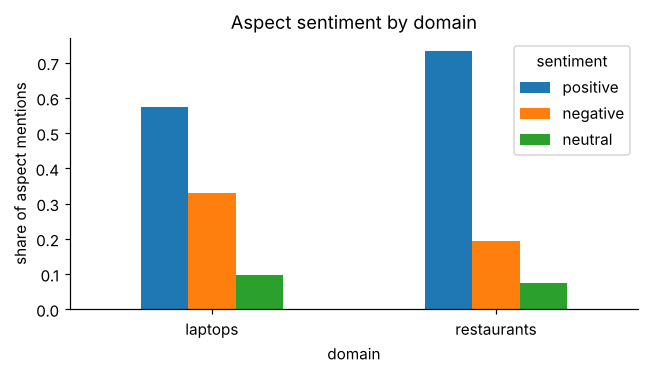

In [ ]:
rows = [(r.domain, r.split, a["sentiment"]) for r in src.itertuples() for a in r.aspects]
sd = pd.DataFrame(rows, columns=["domain", "split", "sentiment"])
tab = pd.crosstab(sd["domain"], sd["sentiment"], normalize="index").round(3)
print(tab)
ax = pd.crosstab(sd["domain"], sd["sentiment"], normalize="index")[["positive", "negative", "neutral"]].plot.bar(rot=0, figsize=(6, 3.5))
ax.set_ylabel("share of aspect mentions"); ax.set_title("Aspect sentiment by domain"); plt.tight_layout(); plt.savefig(FIG / "sentiment_by_domain.png"); plt.show()

## 3. Aspects per sentence and aspect length

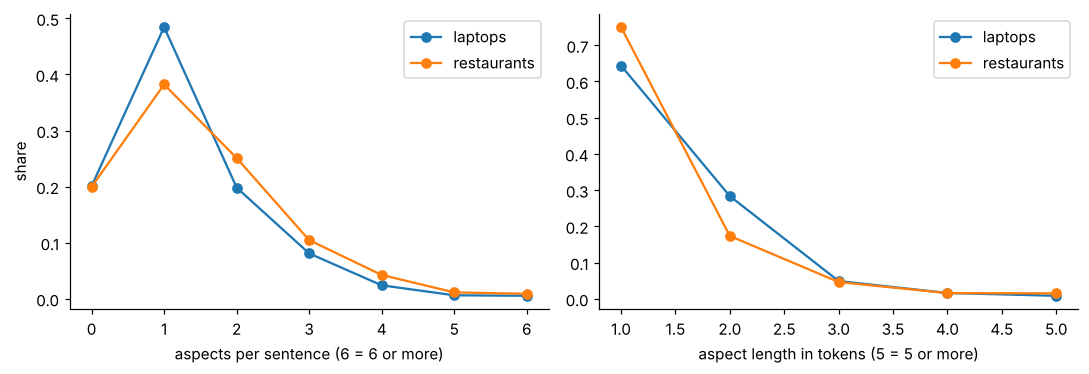

              count  mean   std  min  25%  50%  75%   max
domain                                                   
laptops      2333.0  1.46  0.75  1.0  1.0  1.0  2.0   6.0
restaurants  3905.0  1.40  0.98  1.0  1.0  1.0  1.0  21.0


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for d, g in src[src.split == "train"].groupby("domain"):
    vc = g["n_aspects"].clip(upper=6).value_counts(normalize=True).sort_index()
    axs[0].plot(vc.index, vc.values, marker="o", label=d)
axs[0].set_xlabel("aspects per sentence (6 = 6 or more)"); axs[0].set_ylabel("share"); axs[0].legend()
alen = pd.DataFrame([(r.domain, len(a["aspect"].split())) for r in src.itertuples() for a in r.aspects], columns=["domain", "tokens"])
for d, g in alen.groupby("domain"):
    vc = g["tokens"].clip(upper=5).value_counts(normalize=True).sort_index()
    axs[1].plot(vc.index, vc.values, marker="o", label=d)
axs[1].set_xlabel("aspect length in tokens (5 = 5 or more)"); axs[1].legend()
plt.tight_layout(); plt.savefig(FIG / "aspects_per_sentence.png"); plt.show()
print(alen.groupby("domain")["tokens"].describe().round(2))

## 4. Most frequent aspect terms per source domain

In [ ]:
for d, g in src.groupby("domain"):
    c = collections.Counter(a["aspect"].lower() for r in g.itertuples() for a in r.aspects)
    print(d, "| distinct aspects:", len(c), "| top 15:", [w for w, _ in c.most_common(15)])

laptops | distinct aspects: 851 | top 15: ['screen', 'use', 'price', 'keyboard', 'battery life', 'features', 'battery', 'performance', 'size', 'quality', 'programs', 'os', 'runs', 'works', 'hard drive']
restaurants | distinct aspects: 1124 | top 15: ['food', 'service', 'staff', 'place', 'atmosphere', 'prices', 'pizza', 'sushi', 'menu', 'meal', 'drinks', 'price', 'decor', 'dishes', 'portions']


## 5. Clothing target data

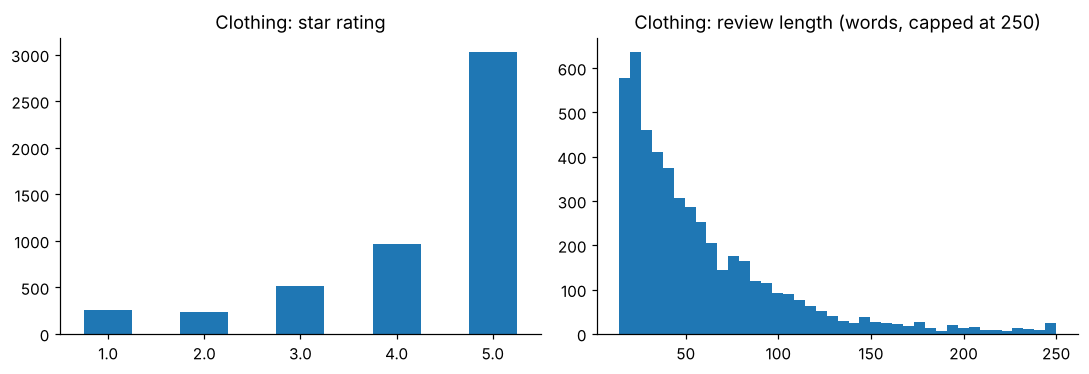

count    5000.0
mean       58.6
std        45.2
min        14.0
25%        26.0
50%        45.0
75%        76.0
max       290.0
Name: n_words, dtype: float64
source sentence length (words), mean: 16.6 | clothing review length, mean: 58.6


In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
clo["rating"].value_counts().sort_index().plot.bar(ax=axs[0], rot=0); axs[0].set_title("Clothing: star rating"); axs[0].set_xlabel("")
axs[1].hist(clo["n_words"].clip(upper=250), bins=40); axs[1].set_title("Clothing: review length (words, capped at 250)")
plt.tight_layout(); plt.savefig(FIG / "clothing_overview.png"); plt.show()
print(clo["n_words"].describe().round(1))
if "department" in clo: print(clo["department"].value_counts().to_dict())
print("source sentence length (words), mean:", round(src["n_words"].mean(), 1), "| clothing review length, mean:", round(clo["n_words"].mean(), 1))

## 6. Domain shift: vocabulary overlap
Frequent noun lemmas per domain (spaCy POS tags), the overlap between the top-N lists, and how many of the clothing top-N nouns never appear anywhere in the source text.

Jaccard overlap of top-200 noun lemmas
             laptops  restaurants  clothing
laptops        1.000        0.117     0.173
restaurants    0.117        1.000     0.136
clothing       0.173        0.136     1.000


clothing top-100 nouns never seen in source text: 22 / 100
['shoe', 'fabric', 'sock', 'waist', 'length', 'earring', 'bra', 'sleeve', 'strap', 'sweater', 'cotton', 'belt', 'leather', 'zipper', 'jacket', 'neck', 'bracelet', 'purse', 'jewelry', 'pattern', 'slipper', 'heel']
top clothing nouns: ['size', 'color', 'shoe', 'shirt', 'quality', 'material', 'time', 'bit', 'fit', 'fabric', 'dress', 'pair', 'foot', 'sock', 'pocket', 'price', 'pant', 'day', 'top', 'one', 'bag', 'year', 'lot', 'watch', 'side']


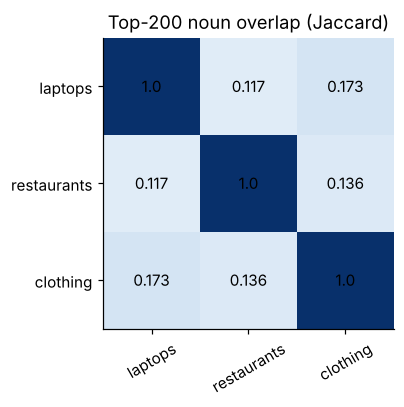

In [ ]:
def top_nouns(texts, n=200):
    c = collections.Counter()
    for doc in nlp.pipe(texts, batch_size=256):
        c.update(t.lemma_.lower() for t in doc if t.pos_ == "NOUN" and t.is_alpha and len(t.lemma_) > 2)
    return c
rng = np.random.RandomState(42)
cnt = {d: top_nouns(g["text"].sample(min(3000, len(g)), random_state=42).tolist()) for d, g in src.groupby("domain")}
cnt["clothing"] = top_nouns(clo["text"].sample(min(3000, len(clo)), random_state=42).tolist())
N = 200
tops = {d: {w for w, _ in c.most_common(N)} for d, c in cnt.items()}
doms = list(tops)
jac = pd.DataFrame([[len(tops[a] & tops[b]) / len(tops[a] | tops[b]) for b in doms] for a in doms], index=doms, columns=doms).round(3)
print("Jaccard overlap of top-%d noun lemmas" % N); print(jac)
src_vocab = set()
for doc in nlp.pipe(src["text"].tolist(), batch_size=256): src_vocab.update(t.lemma_.lower() for t in doc if t.is_alpha)
clo100 = [w for w, _ in cnt["clothing"].most_common(100)]
unseen = [w for w in clo100 if w not in src_vocab]
print("clothing top-100 nouns never seen in source text: %d / 100" % len(unseen)); print(unseen)
print("top clothing nouns:", clo100[:25])
fig, ax = plt.subplots(figsize=(4.8, 3.8)); im = ax.imshow(jac.values, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(doms, rotation=30); ax.set_yticks(range(3)); ax.set_yticklabels(doms)
for i in range(3):
    for j in range(3): ax.text(j, i, jac.values[i, j], ha="center", va="center")
ax.set_title("Top-%d noun overlap (Jaccard)" % N); plt.tight_layout(); plt.savefig(FIG / "noun_overlap.png"); plt.show()

## 5b. Clothing sentences (after preprocessing)
Clothing reviews are split into sentences so the extractors see units comparable to the source domains.

sentences per review: {'count': 5000.0, 'mean': 5.04, 'std': 3.37, 'min': 1.0, '25%': 3.0, '50%': 4.0, '75%': 6.0, 'max': 30.0}
clothing sentence length (words): {'count': 25206.0, 'mean': 11.63, 'std': 7.43, 'min': 1.0, '25%': 6.0, '50%': 10.0, '75%': 15.0, 'max': 91.0}
source sentence length (words): {'count': 4052.0, 'mean': 16.61, 'std': 9.67, 'min': 1.0, '25%': 10.0, '50%': 15.0, '75%': 21.0, 'max': 83.0}


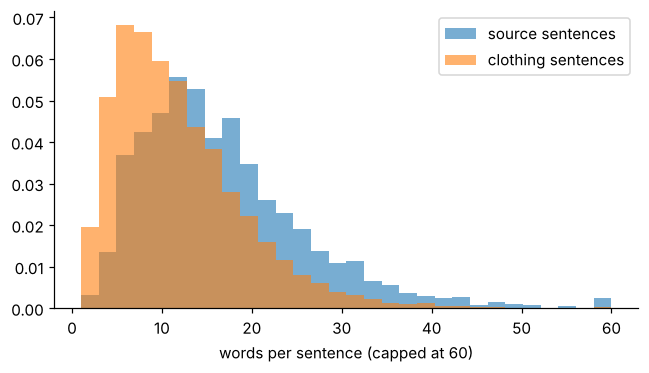

In [ ]:

sent_len = pd.Series([len(s.split()) for ss in clo["sentences"] for s in ss])
print("sentences per review:", clo["n_sent"].describe().round(2).to_dict())
print("clothing sentence length (words):", sent_len.describe().round(2).to_dict())
print("source sentence length (words):", src["n_words"].describe().round(2).to_dict())
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(src["n_words"].clip(upper=60), bins=30, alpha=.6, density=True, label="source sentences")
ax.hist(sent_len.clip(upper=60), bins=30, alpha=.6, density=True, label="clothing sentences")
ax.set_xlabel("words per sentence (capped at 60)"); ax.legend(); plt.tight_layout(); plt.savefig(FIG / "sentence_length_compare.png"); plt.show()


## 5c. Preliminary aspect and sentiment distribution on clothing
There is no clothing gold standard yet, so this is the **baseline system's output**, not gold labels. It shows what the extractor finds on the target domain and is replaced by the gold-set distribution once `data/annotation/gold_labels.jsonl` exists.

In [ ]:

from src import baseline_spacy as bl
sents = [s for ss in clo["sentences"].sample(1500, random_state=42) for s in ss]
preds = bl.predict(sents)
flat = [a for p in preds for a in p]
sc = collections.Counter(a["sentiment"] for a in flat)
print("sentences:", len(sents), "| extracted aspects:", len(flat), "| sentiment share:", {k: round(v / len(flat), 3) for k, v in sc.items()})
print("share of sentences with at least one aspect: %.3f" % (sum(1 for p in preds if p) / len(preds)))
print("top 15 extracted aspects:", [w for w, _ in collections.Counter(a["aspect"] for a in flat).most_common(15)])


sentences: 7734 | extracted aspects: 2477 | sentiment share: {'positive': 0.888, 'negative': 0.112}
share of sentences with at least one aspect: 0.288
top 15 extracted aspects: ['quality', 'fit', 'color', 'shirt', 'size', 'dress', 'shoes', 'colors', 'material', 'price', 'pair', 'fabric', 'socks', 'product', 'design']


## 7. Observations for the report
Figures below come from the Amazon Reviews 2023 sample (5,000 reviews) and the ASTE source splits.

- **Sentiment skew differs by domain.** Positive aspect mentions are 57.5% in laptops and 73.4% in restaurants; negatives are 32.9% and 19.3%. Neutral is 9.6% and 7.3%, so neutral-class F1 will be noisy.
- **Most sentences have one aspect** (median 1, mean about 1.4). About a quarter of train sentences in the final training set have none, added deliberately so the model learns to return `[]`.
- **Aspect vocabulary is domain specific.** Top laptop aspects (screen, battery life, keyboard) and restaurant aspects (food, service, staff) share almost nothing. The Jaccard overlap of the top-200 nouns is 0.12 (laptops vs restaurants), 0.17 (laptops vs clothing) and 0.14 (restaurants vs clothing).
- **22 of the 100 most frequent clothing nouns never occur in the source text** (for example fabric, waist, sleeve, strap, zipper, heel), which supports the cross-domain drop hypothesis.
- **The Amazon category is broader than garments.** Frequent nouns include shoe, sock, earring, bracelet, purse, watch and bag, because Clothing_Shoes_and_Jewelry also holds footwear, jewelry and accessories. State this in the report as the definition of the target domain ("fashion and apparel products"), or filter by product if a stricter clothing domain is wanted.
- **Unit mismatch.** Source items are single sentences (mean 16.6 words); Amazon items are whole reviews (mean 58.6 words, median 45, maximum 290), so `src/prepare_clothing.py` splits reviews into sentences (5.04 per review, mean 11.6 words, close to the source sentences). Any extractor run on clothing uses these sentences.
- **Ratings are skewed to 5 stars** (60.6% five-star, 5.2% one-star, 4.7% two-star), so the gold set is stratified by rating to get enough negative reviews.
- **No reviewer identifiers are present in the sample** and no duplicate review texts; 67.5% of reviews are verified purchases.
- **Clothing preprocessing:** HTML and URLs removed, whitespace normalised, duplicates dropped (none found), sentences split with spaCy. Source preprocessing removed 11 train sentences that were duplicates or also appeared in dev/test (no cross-split leakage remains).
- **Preliminary baseline output on clothing** (not gold): about 29% of clothing sentences yield an aspect and 89% of extracted aspects are positive, which matches the positive skew in ratings. Replace with gold-set distributions after annotation.
